In [1]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

project_dir = Path("/content/drive/MyDrive/Ranepa/ICP")  

data_dir = project_dir / 'data'

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data_file = data_dir / 'AB_NYC_2019.csv'
df = pd.read_csv(data_file)

print("info", df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [5]:
df.isna().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [6]:
(df.isna().mean() * 100).round(2)

,0
id,0.00
name,0.03
host_id,0.00
host_name,0.04
neighbourhood_group,0.00
neighbourhood,0.00
latitude,0.00
longitude,0.00
room_type,0.00
price,0.00


In [7]:
df.nunique()

,0
id,48895
name,47905
host_id,37457
host_name,11452
neighbourhood_group,5
neighbourhood,221
latitude,19048
longitude,14718
room_type,3
price,674


In [8]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [9]:
df.shape


(48895, 16)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]


,0


In [12]:
df['room_type'].value_counts()


,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [13]:
(df['room_type'].value_counts(normalize=True) * 100).round(2)


,proportion
room_type,
Entire home/apt,51.97
Private room,45.66
Shared room,2.37


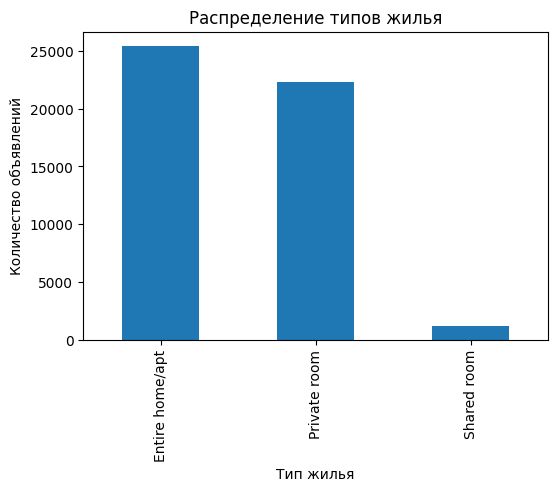

In [26]:
df['room_type'].value_counts().plot(kind='bar', figsize=(6, 4))
plt.title('Распределение типов жилья')
plt.xlabel('Тип жилья')
plt.ylabel('Количество объявлений')
plt.show()


In [15]:
df['neighbourhood_group'].value_counts()


,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


In [32]:
(df['neighbourhood_group'].value_counts(normalize=True) * 100).round(2)


,proportion
neighbourhood_group,
Manhattan,44.30
Brooklyn,41.12
Queens,11.59
Bronx,2.23
Staten Island,0.76


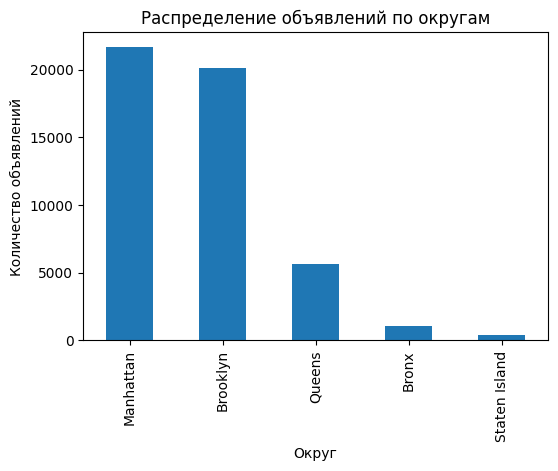

In [27]:
df['neighbourhood_group'].value_counts().plot(kind='bar', figsize=(6, 4))
plt.title('Распределение объявлений по округам')
plt.xlabel('Округ')
plt.ylabel('Количество объявлений')
plt.show()


In [18]:
(df['price'] == 0).sum()


np.int64(11)

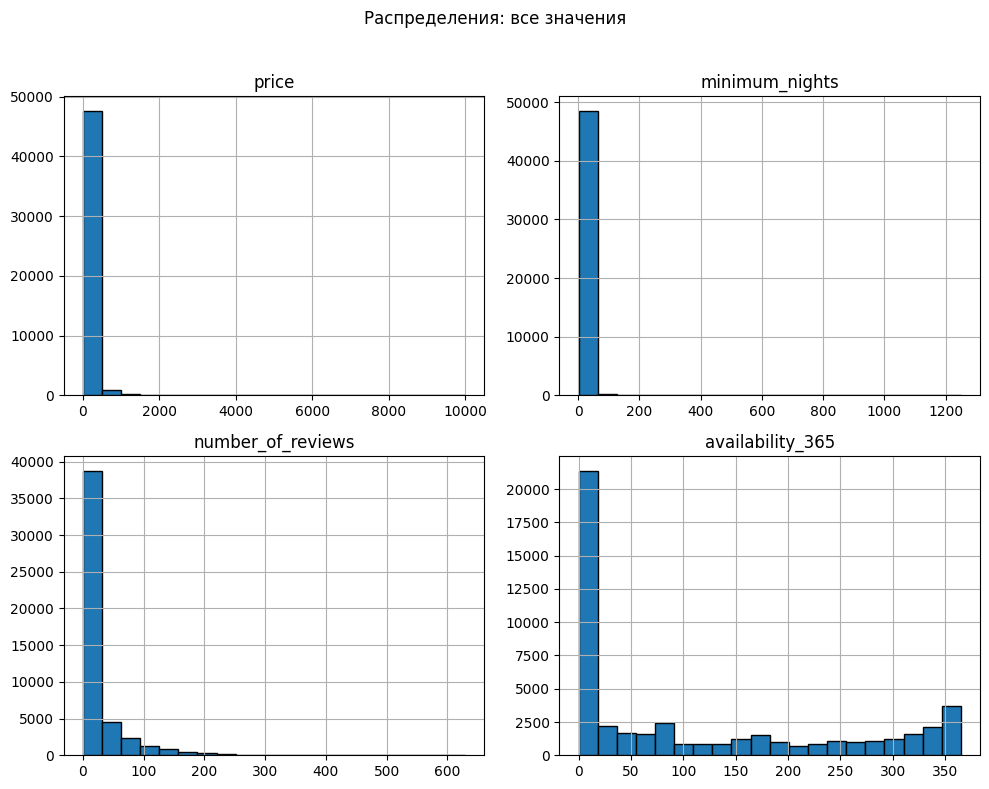

In [19]:
numeric_columns = ['price', 'minimum_nights', 'number_of_reviews', 'availability_365']
df[numeric_columns].hist(bins=20, figsize=(10, 8), edgecolor='black')
plt.suptitle('Распределения: все значения')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


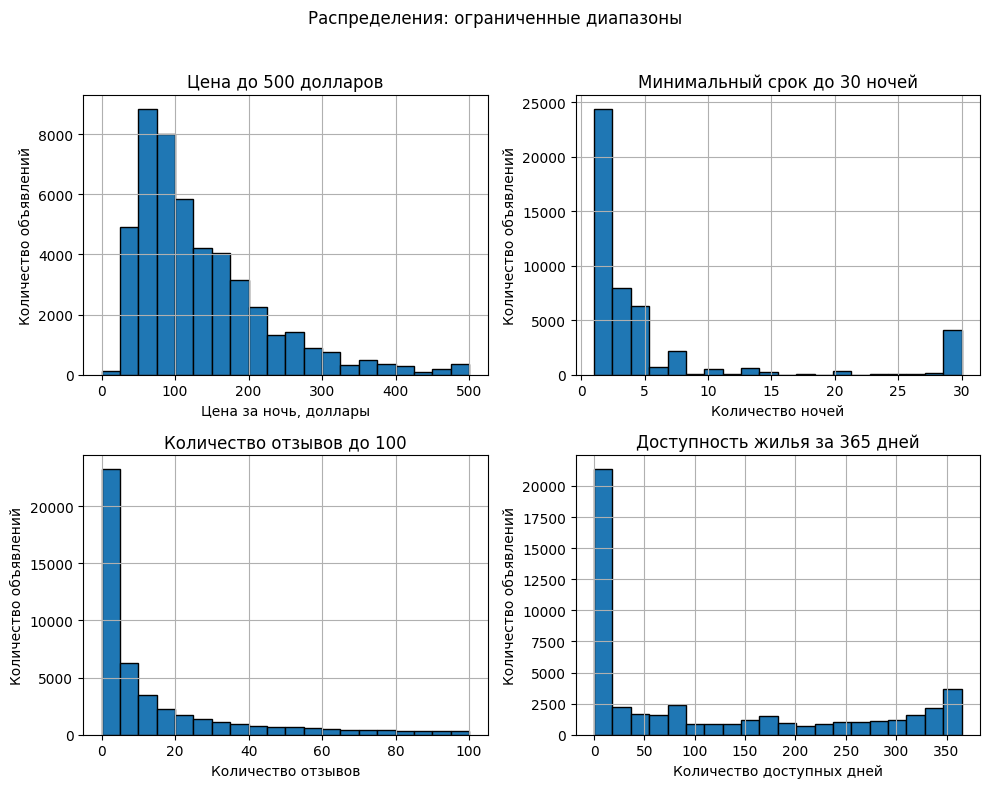

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

df.loc[df['price'] <= 500, 'price'].hist(bins=20, ax=axes[0, 0], edgecolor='black')
axes[0, 0].set_title('Цена до 500 долларов')
axes[0, 0].set_xlabel('Цена за ночь, доллары')

df.loc[df['minimum_nights'] <= 30, 'minimum_nights'].hist(bins=20, ax=axes[0, 1], edgecolor='black')
axes[0, 1].set_title('Минимальный срок до 30 ночей')
axes[0, 1].set_xlabel('Количество ночей')

df.loc[df['number_of_reviews'] <= 100, 'number_of_reviews'].hist(bins=20, ax=axes[1, 0], edgecolor='black')
axes[1, 0].set_title('Количество отзывов до 100')
axes[1, 0].set_xlabel('Количество отзывов')

df['availability_365'].hist(bins=20, ax=axes[1, 1], edgecolor='black')
axes[1, 1].set_title('Доступность жилья за 365 дней')
axes[1, 1].set_xlabel('Количество доступных дней')

for ax in axes.flat:
    ax.set_ylabel('Количество объявлений')

plt.suptitle('Распределения: ограниченные диапазоны')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


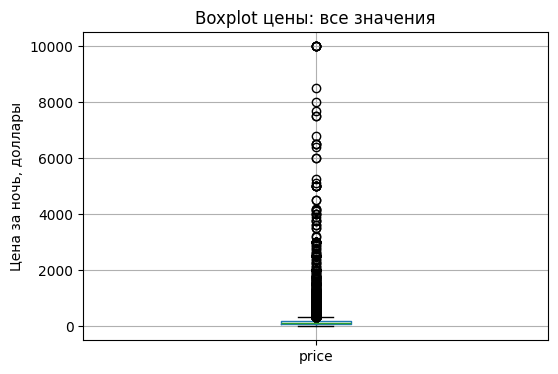

In [21]:
df.boxplot(column='price', figsize=(6, 4))
plt.title('Boxplot цены: все значения')
plt.ylabel('Цена за ночь, доллары')
plt.show()


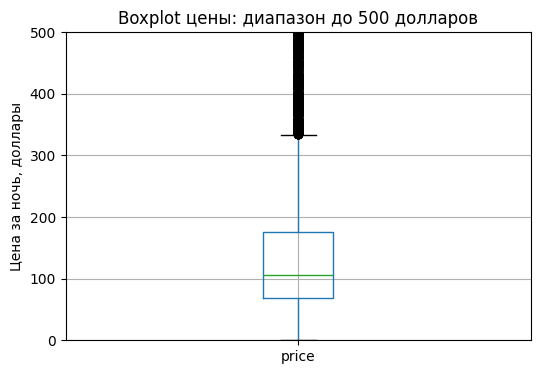

In [22]:
df.boxplot(column='price', figsize=(6, 4))
plt.ylim(0, 500)
plt.title('Boxplot цены: диапазон до 500 долларов')
plt.ylabel('Цена за ночь, доллары')
plt.show()


In [23]:
df.groupby('room_type')['price'].agg(['mean', 'median', 'count']).round(2)


,mean,median,count
room_type,,,
Entire home/apt,211.79,160.0,25409
Private room,89.78,70.0,22326
Shared room,70.13,45.0,1160


In [24]:
df.groupby('neighbourhood_group')['price'].agg(['mean', 'median', 'count']).round(2)


,mean,median,count
neighbourhood_group,,,
Bronx,87.50,65.0,1091
Brooklyn,124.38,90.0,20104
Manhattan,196.88,150.0,21661
Queens,99.52,75.0,5666
Staten Island,114.81,75.0,373


In [25]:
print('Количество строк:', len(df))
print('Количество столбцов:', len(df.columns))
print('Пропущенных ячеек:', df.isna().sum().sum())
print('Полных дубликатов:', df.duplicated().sum())


Количество строк: 48895
Количество столбцов: 16
Пропущенных ячеек: 10089
Полных дубликатов: 0
